In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
#function to draw a rectangle around the given center
def GetLocation(x,y, shift=50, ratio = 20, hight = 100, width = 200):
    center_x = (x+shift)*ratio
    center_y = (shift-y)*ratio
    start_point = (np.int32(center_x+width/2), np.int32(center_y-hight/2))
    end_point = (np.int32(center_x-width/2), np.int32(center_y+hight/2))
    print(start_point, end_point)
    return start_point, end_point

In [2]:
# load data
original_video_path = "/project_scratch/weicheng/stef_data/ori_vid.avi"
gt_fish_path = "/project_scratch/weicheng/stef_data/io_fish_poses.npy"
gt_robot_path = "/project_scratch/weicheng/stef_data/io_robot_poses.npy"

In [3]:
gt_fish = np.load(gt_fish_path)[0,:,:] # get the coordinate of the fish obtain via Berlin
gt_robot = np.load(gt_robot_path)[0,:,:] # the coordinate of the robot via robot sensor
print("Data Length:",len(gt_fish), len(gt_robot)) 

Data Length: 15904 15904


In [4]:
np.max(gt_robot), np.min(gt_robot) #just to get a quick calibration on the coordinate

(46.482093811035156, -45.893646240234375)

In [5]:
idx = 140 # the frame you want to extract foreground and draw contour
offset=50 # the difference between the timestamp from the robot sensor and recorded video

In [6]:
video = cv2.VideoCapture(original_video_path) # read video
video.set(cv2.CAP_PROP_POS_FRAMES, idx+offset) # set the index to extract frame
ret, frame = video.read() # read frame
print("Got",video.get(cv2.CAP_PROP_FRAME_COUNT), "frames") 

Got 16040.0 frames


In [157]:
fgbg = cv2.createBackgroundSubtractorMOG2() # the function to setup background modelling algorithm (there are many)
for k in range(0, 500): # use for a certain number of frames to train the background model
    idx = k
    video.set(cv2.CAP_PROP_POS_FRAMES, idx+offset)
    ret, frame = video.read() 
    fgmask = fgbg.apply(frame) 
    # print(fgmask)
    # print(fgmask.shape, np.max(fgmask), np.min(fgmask))
    # plt.imshow(fgmask, cmap='gray', vmin=0, vmax=255)
    # input()

In [197]:
idx=3001 
video.set(cv2.CAP_PROP_POS_FRAMES, idx+offset)
ret, frame = video.read() 
fgmask = fgbg.apply(frame) 

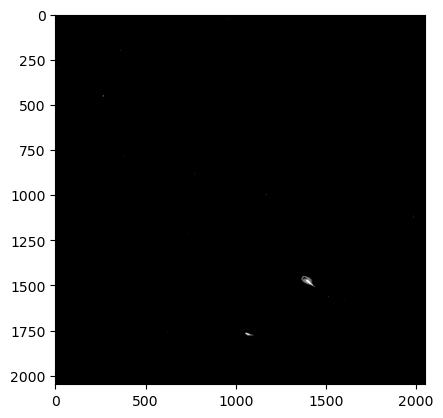

In [198]:
plt.imshow(fgmask, cmap='gray', vmin=0, vmax=255) #show the foreground(white) and background (black)

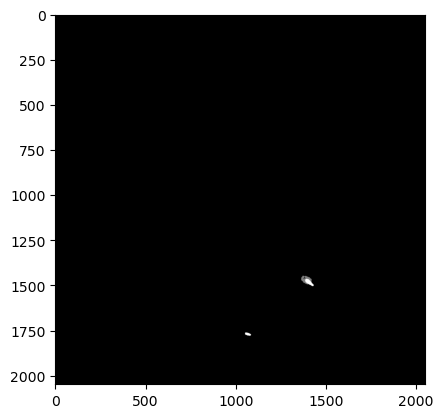

In [199]:
contours, hierarchy = cv2.findContours(fgmask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE) # find contours (the white connected region with certain method and parameters)
mask_con = cv2.drawContours(fgmask, contours, -1, (0,255,0), 3) # draw the found contours on the mask
mask_con = cv2.dilate(mask_con, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10,10)) ) #optional to make the contour more complete and remove some noises
# mask_con = cv2.erode(mask_con, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 1),(0, 0))) #optional to make the contour more complete and remove some noises
plt.imshow(mask_con, cmap='gray', vmin=0, vmax=255)

In [200]:
len(contours) # the number of contours found in the mask; each countour is formed with a lots of points 

72

In [201]:
# optional
# do some hard coding filtering - try to remove the region that is too big/small for a fish
possible_con = []
for k in range(len(contours)):
    if len(contours[k])<400 and len(contours[k])>40:
        possible_con.append(contours[k])
        
del filt_con

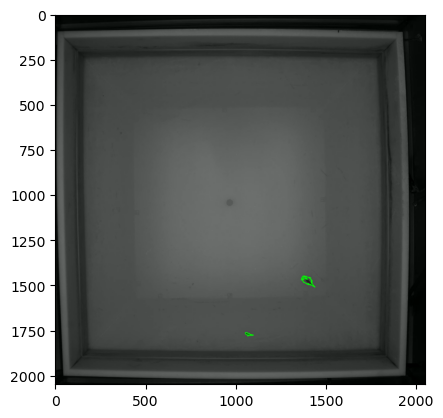

In [202]:
ret, frame = video.read() 
filt_con = cv2.drawContours(frame, possible_con, -1, (0,255,0), 3) #draw contours on the original image 
filt_con = cv2.dilate(filt_con, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1,1)) ) 
# mask_con = cv2.erode(mask_con, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 1),(0, 0)))
plt.imshow(filt_con, cmap='gray', vmin=0, vmax=255)

## Tracking
After you get the contour, you can get the rectangle that includes the whole contour (finding the maximal/minimal of the contour).
Then, you can crop the frame according to the coordinates of the rectangle and apply some feature extraction methods like HOG to get the features of that rectangle.
By comparing the features of each cropped image with consider the coordinate of the previous frame, you can find th

(1390, 750) (1190, 850)


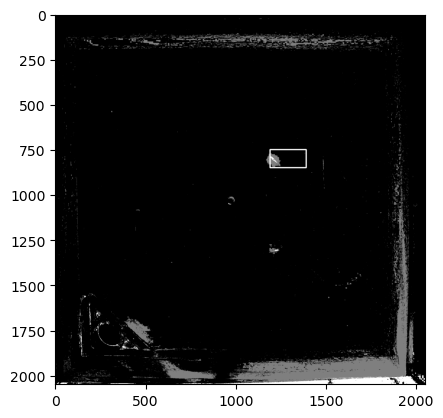

In [36]:
start_point, end_point = GetLocation(gt_robot[idx,0], gt_robot[idx,1])
new_frame = cv2.rectangle(fgmask, start_point, end_point, (255,255,0), 5) 
plt.imshow(new_frame, cmap='gray', vmin=0, vmax=255)

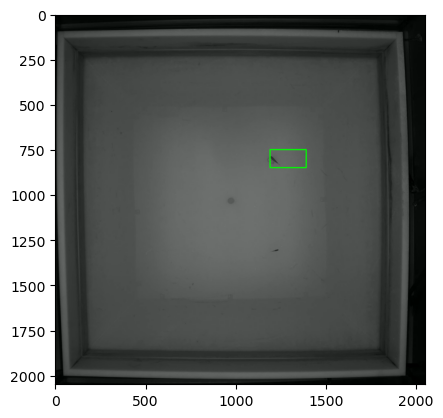

In [37]:
new_frame = cv2.rectangle(frame, start_point, end_point, (0,255,0), 5) 
plt.imshow(new_frame)

(1111, 708) (911, 808)


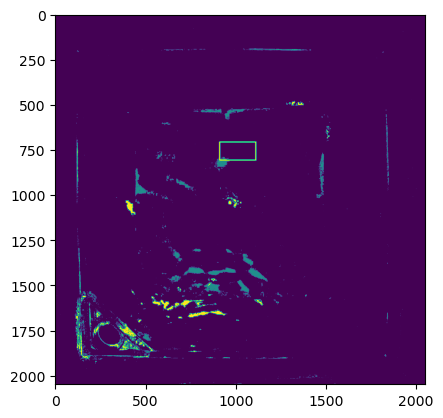

In [20]:
start_point, end_point = GetLocation(gt_robot[idx,0], gt_robot[idx,1])
video.set(cv2.CAP_PROP_POS_FRAMES, idx+offset)
ret, frame = video.read()
new_frame = cv2.rectangle(fgmask, start_point, end_point, (255,0,0), 5) 
plt.imshow(new_frame)

(942, 732) (742, 832)


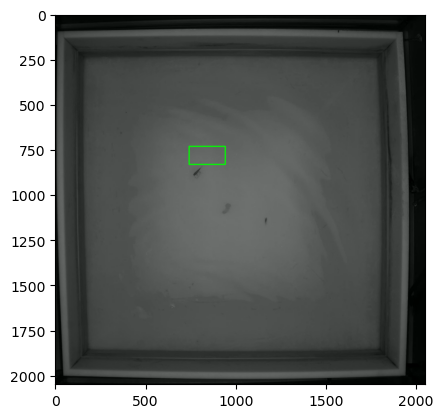

In [247]:
d = 100
start_point, end_point = GetLocation(gt_robot[idx+d,0], gt_robot[idx+d,1])
video.set(cv2.CAP_PROP_POS_FRAMES, idx+offset+d)
ret, frame = video.read()
new_frame = cv2.rectangle(frame, start_point, end_point, (0,255,0), 5) 
plt.imshow(new_frame)